In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "tests"))
TABLES, FIGS, PROC = ROOT / "reports/tables", ROOT / "reports/figures", ROOT / "data/processed"
from olpred.viz import style; style.apply()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

def show(name, width=820):
    display(Image(filename=str(FIGS / name), width=width))

def table(name, **kw):
    return pd.read_csv(TABLES / name, **kw)


# 08 — Final evaluation on the test seasons, ablation, market comparison
Walk-forward 2023 → 2026. Report: `docs/final_evaluation.md`.

In [2]:
table("final_test_table.csv", index_col=0).round(4)

,log_loss,brier,rps,accuracy,f1_macro,f1_draw,ece,roc_auc,log_loss_ci_low,log_loss_ci_high
model,,,,,,,,,,
Class frequency (naive),1.0754,0.6509,0.2305,0.4316,0.2010,0.0000,0.0118,0.4945,1.0689,1.0819
Elo (LogReg),0.9888,0.5900,0.2006,0.5250,0.3909,0.0000,0.0168,0.6583,0.9786,0.9990
Poisson goals,0.9902,0.5905,0.2008,0.5205,0.3877,0.0000,0.0223,0.6614,0.9800,1.0006
LogReg (final),0.9793,0.5834,0.1976,0.5330,0.3993,0.0042,0.0162,0.6689,0.9686,0.9899
Gradient boosting,0.9787,0.5826,0.1974,0.5296,0.3946,0.0028,0.0203,0.6716,0.9679,0.9893
MLP deep (5 seeds),0.9796,0.5834,0.1978,0.5298,0.3960,0.0000,0.0214,0.6710,0.9690,0.9899
Ensemble LogReg+GB+MLP,0.9779,0.5824,0.1973,0.5303,0.3956,0.0000,0.0172,0.6721,0.9673,0.9884
Bookmaker Bet365 (reference),0.9658,0.5740,0.1935,0.5395,0.4049,0.0028,0.0216,0.6856,0.9550,0.9765


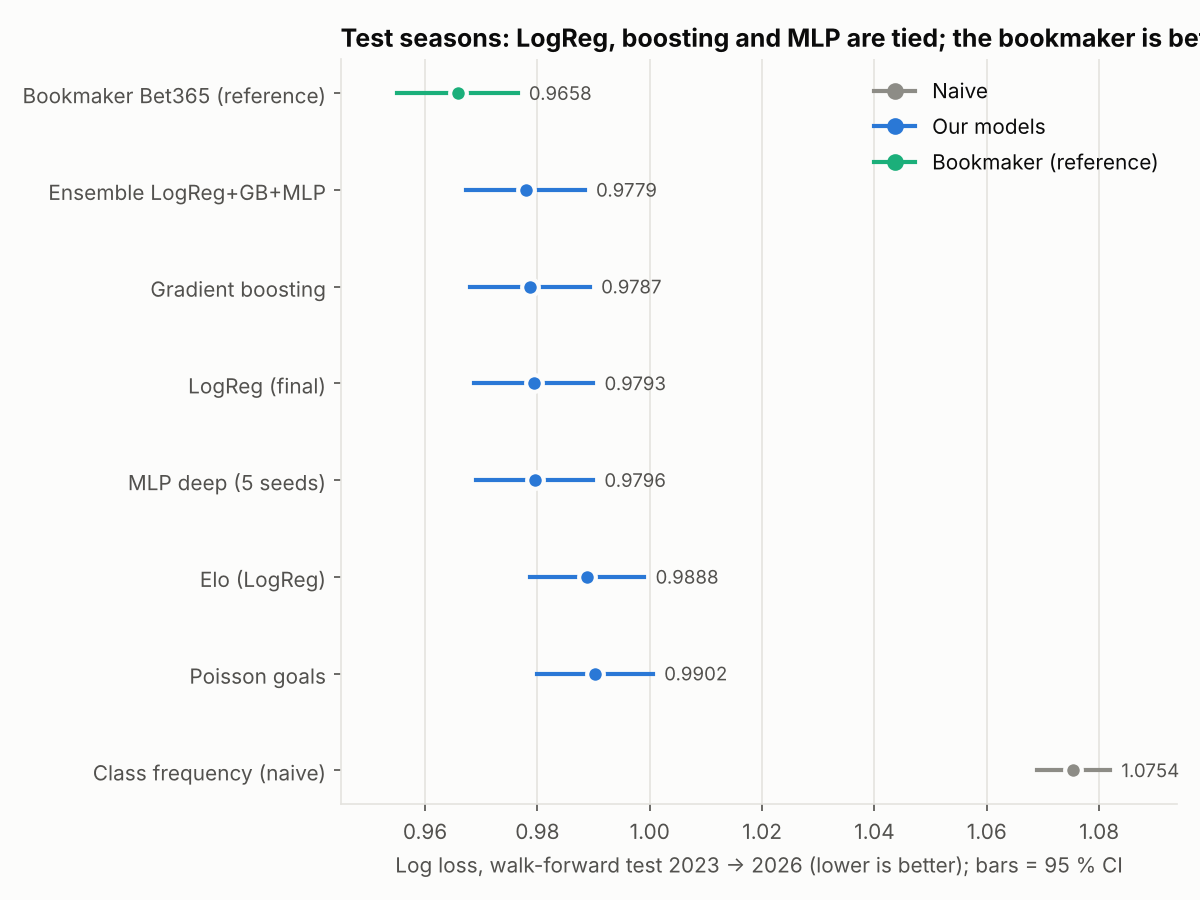

In [3]:
show("final_logloss.png", 800)

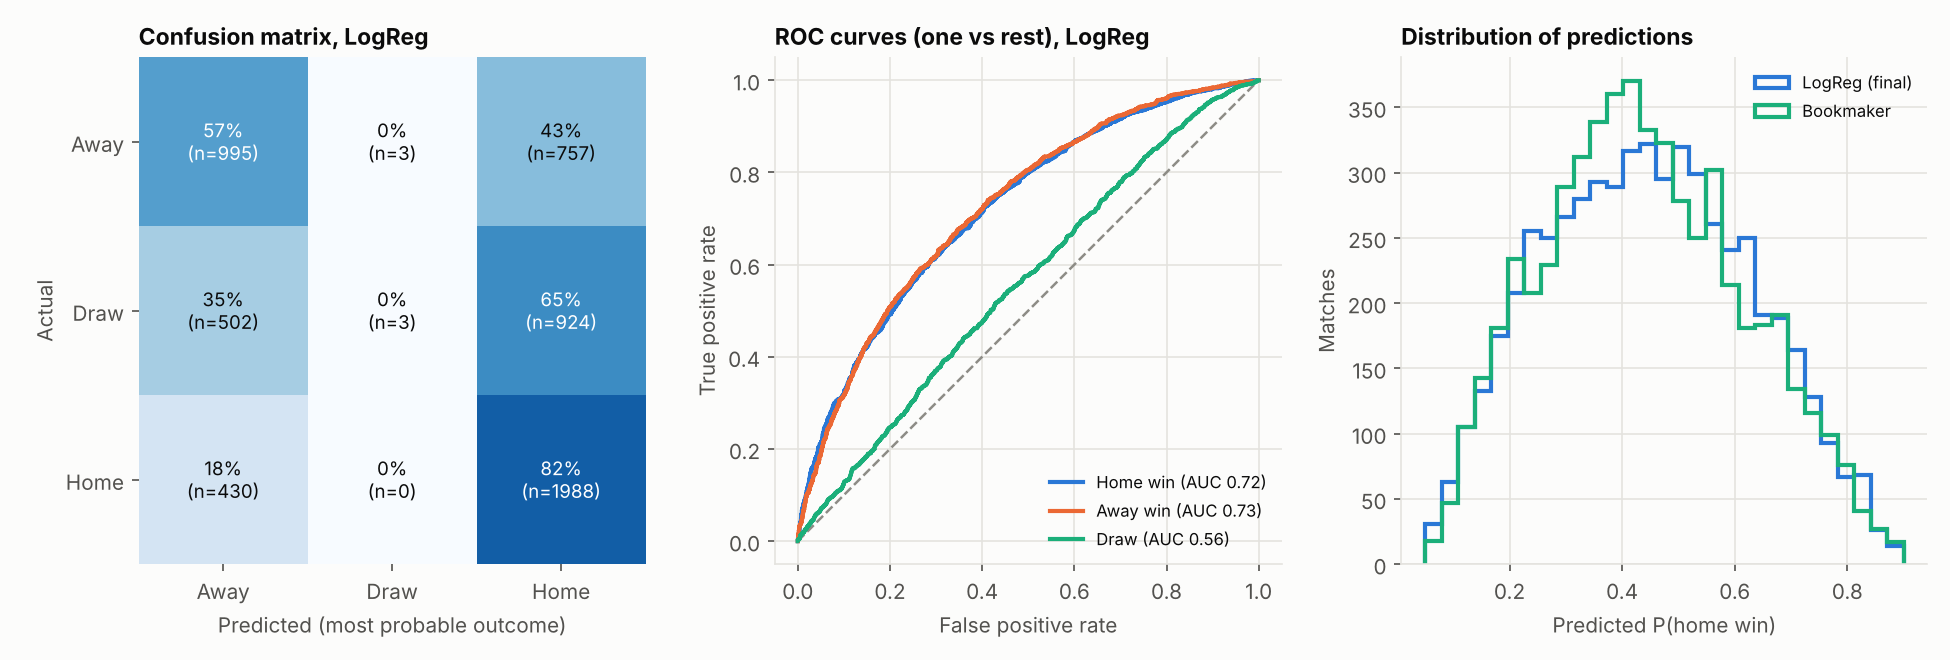

In [4]:
show("final_diagnostics.png", 1000)

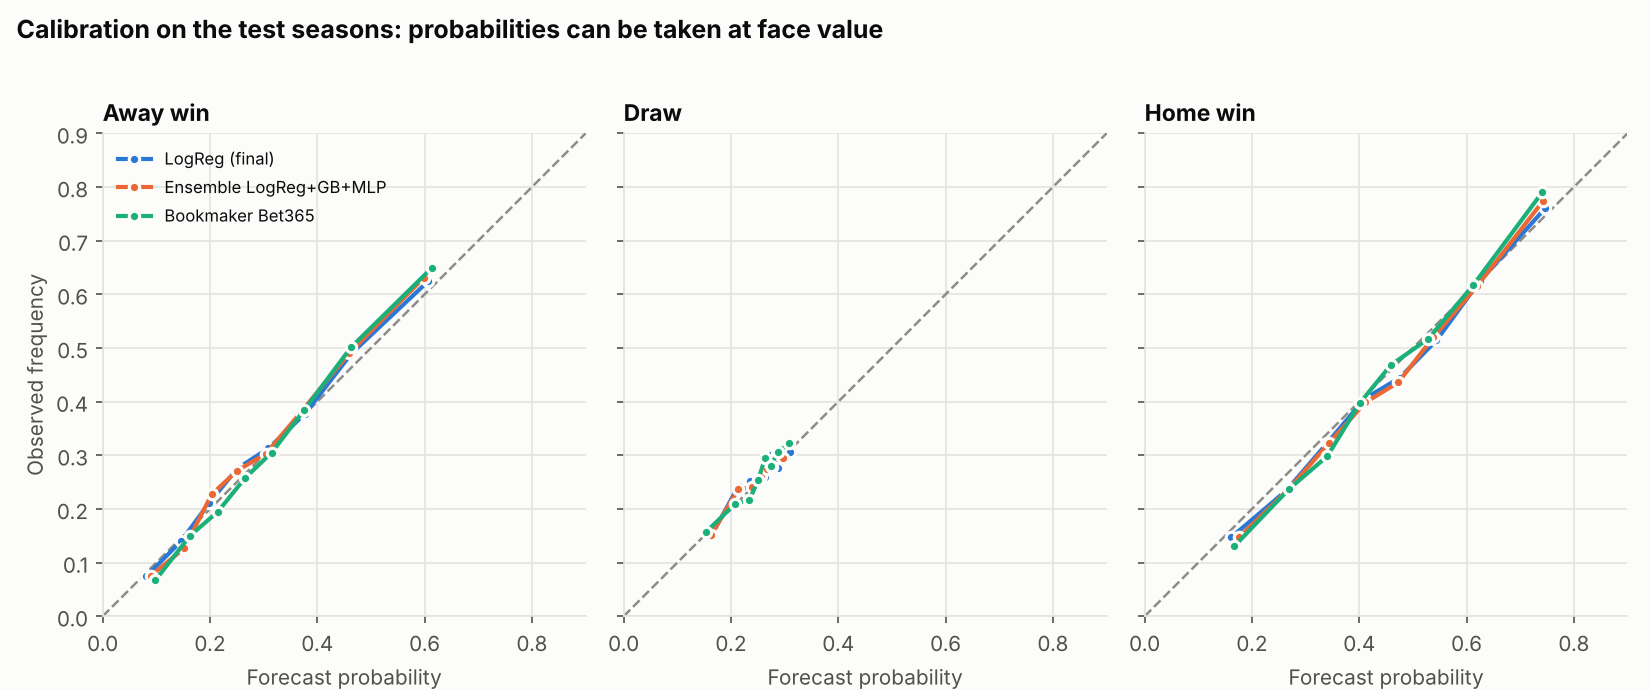

In [5]:
show("final_reliability.png", 980)

### Is the improvement statistically significant?

In [6]:
b = table("final_test_bootstrap.csv"); b[b.vs.isin(["LogReg (final)", "Bookmaker Bet365 (reference)"])].round(4)

,model,vs,diff,ci_low,ci_high,significant
0,Class frequency (naive),LogReg (final),0.0961,0.0868,0.1056,True
2,Class frequency (naive),Bookmaker Bet365 (reference),0.1095,0.1002,0.1189,True
3,Elo (LogReg),LogReg (final),0.0095,0.0056,0.0135,True
4,Elo (LogReg),Bookmaker Bet365 (reference),0.0230,0.0188,0.0271,True
5,Poisson goals,LogReg (final),0.0109,0.0071,0.0147,True
7,Poisson goals,Bookmaker Bet365 (reference),0.0244,0.0205,0.0282,True
9,LogReg (final),Bookmaker Bet365 (reference),0.0135,0.0094,0.0175,True
10,Gradient boosting,LogReg (final),-0.0007,-0.0032,0.0018,False
12,Gradient boosting,Bookmaker Bet365 (reference),0.0128,0.0089,0.0167,True
13,MLP deep (5 seeds),LogReg (final),0.0003,-0.0016,0.0022,False


### Do the models add information beyond the bookmaker? (log-linear pooling)

In [7]:
table("final_test_market_pooling.csv").round(4)

,model,weight_chosen_on_validation,pooled_log_loss,market_log_loss,diff_vs_market,ci_low,ci_high,significant,weight_best_in_sample_on_test
0,LogReg (final),0.15,0.9663,0.9658,0.0005,-0.0001,0.0011,False,0.0
1,Ensemble LogReg+GB+MLP,0.15,0.9664,0.9658,0.0006,0.0000,0.0011,True,0.0


### Ablation (validation)

In [8]:
display(table("ablation_cumulative.csv")[["config", "n_columns", "log_loss", "brier", "accuracy"]].round(4)); display(table("ablation_steps_bootstrap.csv").round(4)); display(table("ablation_leave_one_out.csv")[["config", "log_loss", "delta_vs_full", "ci_low", "ci_high"]].round(4))

,config,n_columns,log_loss,brier,accuracy
0,A: Elo only,4,0.9957,0.5936,0.5240
1,"B: + results form (3/5/10 matches, venue)",43,0.9931,0.5918,0.5292
2,C: + shots and xG proxy,79,0.9887,0.5891,0.5286
3,"D: + league table, fatigue",94,0.9890,0.5893,0.5256
4,E: + squad market value (= final model),100,0.9870,0.5874,0.5294
5,Elo + squad value only,10,0.9916,0.5904,0.5311


,step,diff,ci_low,ci_high,significant
0,A -> B,-0.0026,-0.0051,-0.0001,True
1,B -> C,-0.0044,-0.0072,-0.0017,True
2,C -> D,0.0003,-0.0013,0.0019,False
3,D -> E,-0.0020,-0.0048,0.0009,False


,config,log_loss,delta_vs_full,ci_low,ci_high
0,all minus Elo rating,0.9895,0.0025,0.0004,0.0045
1,all minus Fatigue / schedule,0.9871,0.0001,-0.0011,0.0012
2,all minus League table,0.9866,-0.0004,-0.0013,0.0005
3,all minus Recent form (3/5/10 matches),0.9877,0.0007,-0.0008,0.0021
4,all minus Shots (on target / against),0.9870,-0.0000,-0.0002,0.0002
5,all minus Squad market value,0.9890,0.0020,-0.0009,0.0048
6,all minus Venue form (home/away),0.9866,-0.0004,-0.0012,0.0003
7,all minus xG proxy,0.9870,-0.0000,-0.0002,0.0002


### How much is irreducible noise?

In [9]:
table("final_test_noise_floor.csv")

,quantity,value
0,Mean entropy of bookmaker probabilities,0.9871
1,Mean entropy of final LogReg probabilities,0.9791
2,"Realised log loss, bookmaker",0.9658
3,"Realised log loss, final LogReg",0.9793
4,"Realised log loss, naive frequencies",1.0754
